# Databehandling – afdæmpet fjeder med IOLab

**Mekanik og fysisk modellering (10033)**. Vi har målt kraft $F(t)$ i newton (CSV-kolonnen `cal[0]`). Vi analyserer svingningsperiode, aftagende amplitude, dæmpningskonstant og fjederkonstant.

Metoden svarer til kursets arbejde med grafer, regression og usikkerheder: vis data → udtræk måleværdier → regressionsanalyse → sammenlign med fysikmodellen → vurder usikkerheder.

**Antagelser:** Massen på 0,200 kg er den *samlede bevægende masse*, og 0,101 m er fjederens forlængelse fra ubelastet længde i statisk ligevægt. Hvis de ikke passer, skal beregningen af fjederkonstant rettes. IOLabs negative kraft skyldes sandsynligvis sensorens fortegnskonvention.

Placér `Mekanik_forsøg.csv` i samme mappe som denne notebook. Ingen af de to råfiler (`.raw`/`.bson`) er nødvendige, når CSV'en allerede indeholder den kalibrerede kraftmåling.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

m = 0.200               # kg, oplyst bevægende masse
g = 9.82                # m/s^2
L_start = 0.200         # m, forlængelse ved start fra ubelastet længde
L_ligevaegt = 0.101     # m, forlængelse i ligevægt fra ubelastet længde

fil = 'Mekanik_forsøg.csv'
df = pd.read_csv(fil)
df.columns = df.columns.str.strip()
t_raw = df['time'].to_numpy()
F_raw = df['cal[0]'].to_numpy()

print(f'Målepunkter: {len(F_raw):,}')
print(f'Tidsinterval: {t_raw.min():.3f}–{t_raw.max():.3f} s')
print(f'Middelkraft: {np.mean(F_raw):.4f} N')
print(f'Standardafvigelse over hele serien: {np.std(F_raw, ddof=1):.4f} N')
print('NB: Denne standardafvigelse indeholder selve svingningerne og er IKKE sensorens måleusikkerhed.')

Målepunkter: 555,480
Tidsinterval: 0.000–120.000 s
Middelkraft: -2.3418 N
Standardafvigelse over hele serien: 0.4318 N
NB: Denne standardafvigelse indeholder selve svingningerne og er IKKE sensorens måleusikkerhed.


## 1. Oversigt over tidsserien

Der er ca. en halv million målepunkter. Vi samler derfor **46 nabomålinger i ét middelpunkt** for at kunne vise kurven overskueligt. Dette ændrer kun lidt på svingninger på ca. 0,82 s. CSV'ens `time`-værdier er afrundet forskelligt, så vi bruger blokmiddelværdi af tidsstemplerne.


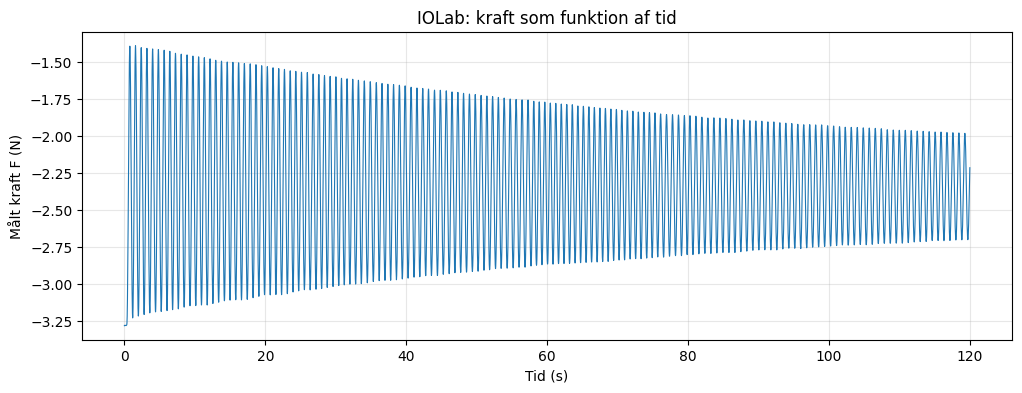

In [2]:
blok = 46
n = len(F_raw) // blok
t = t_raw[:n*blok].reshape(n, blok).mean(axis=1)
F = F_raw[:n*blok].reshape(n, blok).mean(axis=1)

# Let udglatning for at undgå støjtoppe ved automatisk topdetektion.
F_glat = gaussian_filter1d(F, sigma=1.5)

plt.figure(figsize=(12, 4))
plt.plot(t, F_glat, linewidth=0.8)
plt.xlabel('Tid (s)')
plt.ylabel('Målt kraft F (N)')
plt.title('IOLab: kraft som funktion af tid')
plt.grid(alpha=0.3)
plt.show()


## 2. Svingningstiden fra toppunkter

Hvis et positivt kraftmaksimum kommer ved tid $t_i$, er én svingningstid

$$T_i=t_{i+1}-t_i.$$

Vi finder toppunkterne automatisk med `scipy.signal.find_peaks`. Da perioden ændrer sig lidt under forsøget, beregner vi både gennemsnit, spredning og en tidsserie af de enkelte perioder.


Toppe: 145; bunde: 145
Middelperiode: T = 0.8229 s
Spredning mellem perioder: 0.0253 s (ikke det samme som usikkerhed på middelværdien)
Dæmpet vinkelfrekvens: omega_d = 7.6351 rad/s


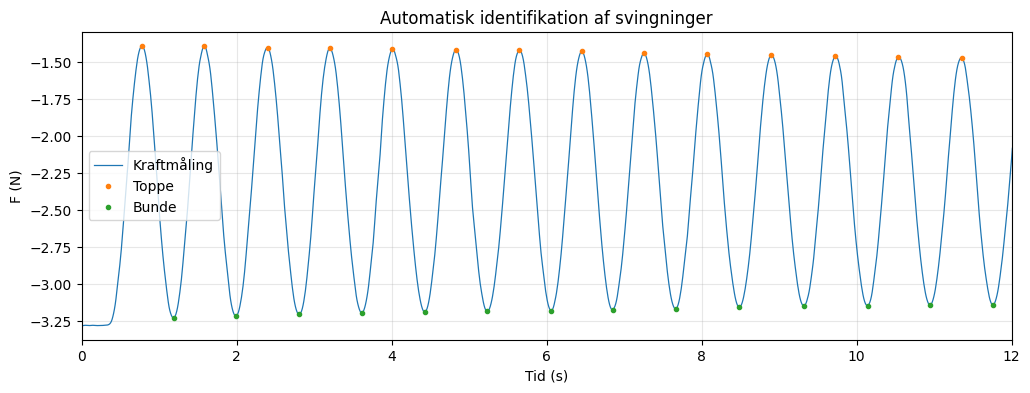

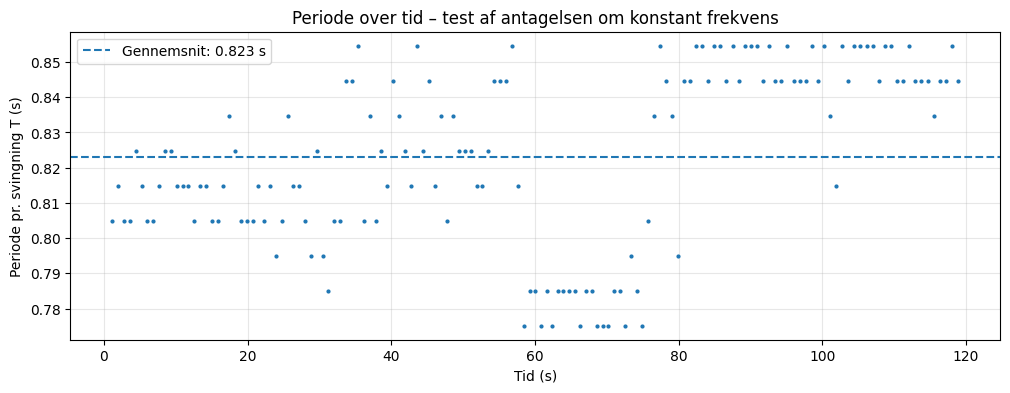

  1– 30 s: T = 0.8124 s; spredning 0.0096 s; n=36
 30– 60 s: T = 0.8234 s; spredning 0.0206 s; n=36
 60– 90 s: T = 0.8095 s; spredning 0.0331 s; n=37
 90–119 s: T = 0.8475 s; spredning 0.0082 s; n=35


In [3]:
sampling = 1 / np.mean(np.diff(t))
toppe, _ = find_peaks(F_glat, distance=int(0.60*sampling), prominence=0.15)
bunde, _ = find_peaks(-F_glat, distance=int(0.60*sampling), prominence=0.15)

t_top = t[toppe]
F_top = F_glat[toppe]
t_bund = t[bunde]
F_bund = F_glat[bunde]
T_i = np.diff(t_top)
t_T = (t_top[:-1] + t_top[1:])/2
T_gns = np.mean(T_i)
T_spredning = np.std(T_i, ddof=1)
omega_d = 2*np.pi / T_gns

print(f'Toppe: {len(toppe)}; bunde: {len(bunde)}')
print(f'Middelperiode: T = {T_gns:.4f} s')
print(f'Spredning mellem perioder: {T_spredning:.4f} s (ikke det samme som usikkerhed på middelværdien)')
print(f'Dæmpet vinkelfrekvens: omega_d = {omega_d:.4f} rad/s')

plt.figure(figsize=(12, 4))
plt.plot(t, F_glat, linewidth=0.9, label='Kraftmåling')
plt.plot(t_top, F_top, '.', label='Toppe')
plt.plot(t_bund, F_bund, '.', label='Bunde')
plt.xlim(0, 12)
plt.xlabel('Tid (s)')
plt.ylabel('F (N)')
plt.title('Automatisk identifikation af svingninger')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t_T, T_i, '.', markersize=4)
plt.axhline(T_gns, linestyle='--', label=f'Gennemsnit: {T_gns:.3f} s')
plt.xlabel('Tid (s)')
plt.ylabel('Periode pr. svingning T (s)')
plt.title('Periode over tid – test af antagelsen om konstant frekvens')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for start, slut in [(1, 30), (30, 60), (60, 90), (90, 119)]:
    maske = (t_T >= start) & (t_T < slut)
    print(f'{start:3d}–{slut:3d} s: T = {np.mean(T_i[maske]):.4f} s; '
          f'spredning {np.std(T_i[maske], ddof=1):.4f} s; n={np.sum(maske)}')


## 3. Dæmpning ud fra amplituden

Kraften oscillerer omkring en ligevægtsværdi. Vi beregner amplituden af hvert sving som halvdelen af forskellen mellem et maksimum og det efterfølgende minimum:

$$A_i=\frac{F_{\mathrm{maks},i}-F_{\mathrm{min},i}}{2}.$$

For en lineært afdæmpet oscillator forventes en eksponentiel amplitudekurve,

$$A(t)=A_0e^{-\gamma t},$$

så **logaritmen kan regressionsanalyseres som en ret linje**:

$$\ln A(t)=\ln A_0-\gamma t.$$

Her er $\gamma$ dæmpningskonstanten i $\mathrm{s}^{-1}$. Parameterusikkerheden fra `curve_fit` beskriver fitspredning *under antagelsen om den valgte model*; den inkluderer ikke instrumentkalibrering eller modelafvigelser.


Dæmpning: gamma = (0.007982 ± 0.000035) 1/s [kun fit-usikkerhed]
R² for logaritmisk regression: 0.99733
Ekstrapoleret amplitude ved t=0: A0 = 0.9011 N
Amplitudens halveringstid: ln(2)/gamma = 86.8 s
Relativ energi efter 120 s, hvis E proportional med A²: 0.147


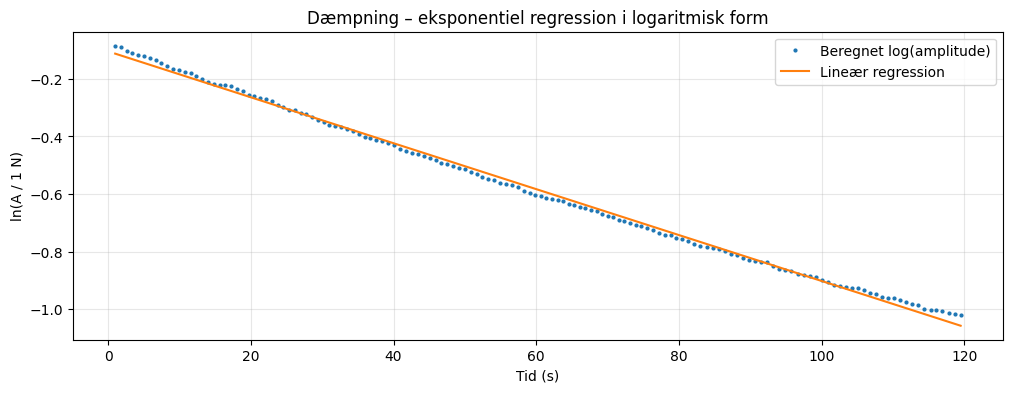

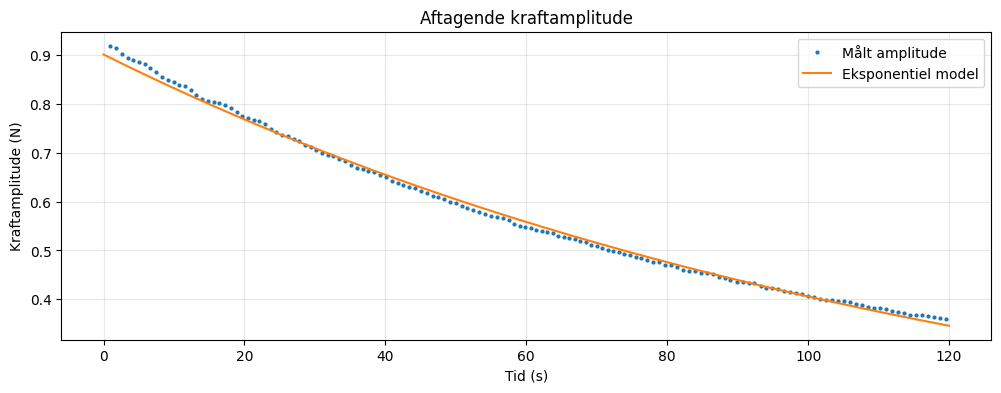

In [4]:
# Hvert maksimum matches med det næste minimum.
ind = np.searchsorted(t_bund, t_top)
gyldig = ind < len(t_bund)
ind = ind[gyldig]
t_amplitude = (t_top[gyldig] + t_bund[ind])/2
A = (F_top[gyldig] - F_bund[ind])/2
F_midtpunkter = (F_top[gyldig] + F_bund[ind])/2

assert np.all(A > 0), 'Nogle amplituder er ikke positive – kontrollér topdetektionen.'

def logmodel(t, lnA0, gamma):
    return lnA0 - gamma*t

param, cov = curve_fit(logmodel, t_amplitude, np.log(A))
lnA0, gamma = param
delta_lnA0, delta_gamma = np.sqrt(np.diag(cov))
A0 = np.exp(lnA0)
log_fit = logmodel(t_amplitude, *param)
R2 = 1 - np.sum((np.log(A)-log_fit)**2) / np.sum((np.log(A)-np.mean(np.log(A)))**2)

print(f'Dæmpning: gamma = ({gamma:.6f} ± {delta_gamma:.6f}) 1/s [kun fit-usikkerhed]')
print(f'R² for logaritmisk regression: {R2:.5f}')
print(f'Ekstrapoleret amplitude ved t=0: A0 = {A0:.4f} N')
print(f'Amplitudens halveringstid: ln(2)/gamma = {np.log(2)/gamma:.1f} s')
print(f'Relativ energi efter 120 s, hvis E proportional med A²: {np.exp(-2*gamma*120):.3f}')

plt.figure(figsize=(12, 4))
plt.plot(t_amplitude, np.log(A), '.', markersize=4, label='Beregnet log(amplitude)')
plt.plot(t_amplitude, log_fit, label='Lineær regression')
plt.xlabel('Tid (s)')
plt.ylabel('ln(A / 1 N)')
plt.title('Dæmpning – eksponentiel regression i logaritmisk form')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t_amplitude, A, '.', markersize=4, label='Målt amplitude')
plt.plot(t, A0*np.exp(-gamma*t), label='Eksponentiel model')
plt.xlabel('Tid (s)')
plt.ylabel('Kraftamplitude (N)')
plt.title('Aftagende kraftamplitude')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. Hookes lov – to uafhængige estimater af fjederkonstanten

**Statisk:** $k_{\rm statisk}=mg/\Delta L_{\rm ligevægt}$.

**Dynamisk:** For en **ideal** fjeder med bevægende masse $m$ gælder $\omega_0^2=k/m$. For svag viskos dæmpning med $x(t)\propto e^{-\gamma t}\cos(\omega_d t+\phi)$ gælder mere præcist $\omega_0^2=\omega_d^2+\gamma^2$, altså

$$k_{\rm dynamisk}=m\bigl[(2\pi/T)^2+\gamma^2\bigr].$$

De to måder *bør* give samme værdi, hvis modelantagelserne og massen er korrekte. **De gør det ikke i disse data**, og uoverensstemmelsen skal diskuteres i rapporten. Én kraft-tidsmåling kan ikke etablere Hookes lov direkte som en ret linje i et $(x,F)$-diagram; det kræver position eller flere statiske forlængelser/kræfter.


In [5]:
k_statisk = m*g/L_ligevaegt
k_dynamisk = m*(omega_d**2 + gamma**2)
T_forventet = 2*np.pi / np.sqrt(k_statisk/m - gamma**2)
A_start = L_start-L_ligevaegt
F_ligevaegt_maal = np.mean(F_raw)

print(f'Startamplitude ift. ligevægt: {A_start:.3f} m')
print(f'k_statisk = {k_statisk:.3f} N/m')
print(f'k_dynamisk = {k_dynamisk:.3f} N/m')
print(f'Afvigelse relativt til statisk k: {100*(k_statisk-k_dynamisk)/k_statisk:.1f} %')
print(f'Forventet T ud fra statisk k: {T_forventet:.4f} s; målt: {T_gns:.4f} s')
print(f'Middel-F målt af IOLab: {F_ligevaegt_maal:.3f} N')
print(f'Forventet |F| fra mg = {m*g:.3f} N (hvis ingen sensor-offset eller ekstra masse)')
print(f'Modsvarende masse fra |middel-F|/g = {abs(F_ligevaegt_maal)/g:.3f} kg')


Startamplitude ift. ligevægt: 0.099 m
k_statisk = 19.446 N/m
k_dynamisk = 11.659 N/m
Afvigelse relativt til statisk k: 40.0 %
Forventet T ud fra statisk k: 0.6372 s; målt: 0.8229 s
Middel-F målt af IOLab: -2.342 N
Forventet |F| fra mg = 1.964 N (hvis ingen sensor-offset eller ekstra masse)
Modsvarende masse fra |middel-F|/g = 0.238 kg


## 5. Usikkerheder og kontrol

- Der mangler oplyst usikkerhed på massen $\delta m$, den statiske forlængelse $\delta L$ og sensorens kalibrering. **Indsæt ikke vilkårlige ±-værdier.**
- Hvis $m$ og $\Delta L$ er målt uafhængigt, giver fejlophobningsloven (hvis $g$ er taget som eksakt) $\delta k_{\rm statisk}/k_{\rm statisk}=\sqrt{(\delta m/m)^2+(\delta L/\Delta L)^2}$.
- For svag dæmpning er $\delta k_{\rm dynamisk}/k_{\rm dynamisk}\approx\sqrt{(\delta m/m)^2+(2\delta T/T)^2}$.
- **Spredningen mellem enkelte svingningsperioder er ikke automatisk parameterusikkerhed.** Perioden driver gennem forsøget. Et lille fit-standard-error kan derfor ikke gøre modellen sikker.
- Når IOLab viser $\sigma\approx0.43\ \mathrm N$, kommer tallet primært fra selve svingningerne, ikke tilfældig instrumentstøj.
- Kontrollér om den reelt bevægende masse inkluderer andet end 200 g, om forlængelsen 10,1 cm virkelig måles i forhold til ubelastet længde, og om der er offset på kraftmåleren.

**Valgfri accelerationsberegning:** Hvis den viste kraft har *modsat fortegn* af fjedertrækket på massen, og den samlede bevægende masse faktisk er $m$, kan den oscillierende del af accelerationen estimeres som $a_{\rm osc}(t)=-[F(t)-F_{\rm eq}]/m$. Dette er en relativ acceleration, ikke et selvstændigt mål for tyngdeaccelerationen; det korrigerer ikke en ukendt sensoroffset.


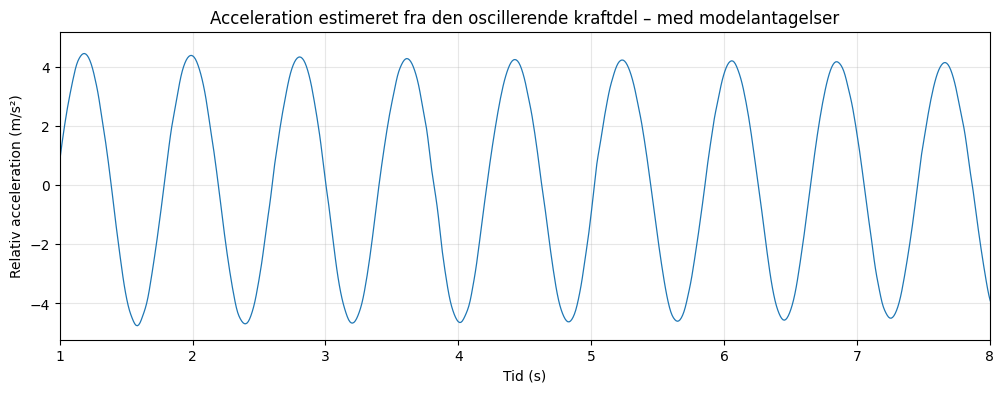

In [6]:
# Kun illustrativt: acceleration af den oscillerende bevægelse
# under antagelsen om at den målte kraft har modsat fortegn af fjedertrækket.
a_osc = -(F_glat - np.mean(F_raw)) / m
plt.figure(figsize=(12, 4))
plt.plot(t, a_osc, linewidth=0.9)
plt.xlim(1, 8)
plt.xlabel('Tid (s)')
plt.ylabel('Relativ acceleration (m/s²)')
plt.title('Acceleration estimeret fra den oscillerende kraftdel – med modelantagelser')
plt.grid(alpha=0.3)
plt.show()


## 6. Hvad kan konkluderes?

1. Målingens kraftamplitude aftager omtrent eksponentielt; den valgte dæmpningsmodel passer godt til *amplitudernes logaritme*.
2. Perioden er ca. 0,82 s, men er ikke helt konstant: den simple model med konstant $k$ og konstant $m$ beskriver ikke alle detaljer.
3. Den statiske og dynamiske bestemmelse af $k$ stemmer ikke overens. Derfor kan vi ikke uden yderligere målinger hævde, at forsøget kvantitativt bekræfter Hookes lov.
4. En stærkere test kræver en supplerende måleserie af $(\Delta L,F)$ i statisk ligevægt, eller position $x(t)$ samtidig med kraften.

**Forslag til rapport:** Vis original $F(t)$, perioder over tid, log(amplitude)-regression, modelparametre med usikkerhed og en særskilt diskussion af systematiske afvigelser. Brug undervisningens fremgangsmåde med `curve_fit`, kovariansmatrix, `np.sqrt(np.diag(cov))` og usikkerhedsregnskab.
